# DSC2107 Group 8 — itch.io Top Sellers Analysis



In [3]:
from pathlib import Path
import sqlite3, re
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "data").is_dir() and (ROOT.parent / "data").is_dir():
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "cleaned"
DB = ROOT / "data" / "group8_itchio.sqlite"
plt.rcParams["figure.figsize"] = (10, 5.5)

## 1. Load real collected data when available

In [4]:
csv_files = sorted(PROC.glob("*.csv"))
if not csv_files:
    csv_files = sorted(RAW.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No real CSV snapshots found in {PROC} or {RAW}")

frames = []
for file_path in csv_files:
    try:
        frames.append(pd.read_csv(file_path))
    except Exception as error:
        print("Could not read", file_path.name, error)
if not frames:
    raise ValueError("No readable real CSV snapshots were found.")

df = pd.concat(frames, ignore_index=True)
for expected, actual in {
    "url": "game_url",
    "price_text": "price",
    "genres": "genre",
    "source_page": "listing_page",
}.items():
    if expected not in df and actual in df:
        df[expected] = df[actual]
DATA_MODE = f"COLLECTED CSV FILES — {len(frames)} real snapshot(s); verify dates and provenance"
print("DATA MODE:", DATA_MODE, "| rows:", len(df))
display(df.head())

DATA MODE: COLLECTED CSV FILES — 7 real snapshot(s); verify dates and provenance | rows: 3500


,rank,title,developer,price,genre,platforms,game_url,listing_page,scraped_at,price_value,url,price_text,genres,source_page
0,1,The Choicer Voicer,YeahMaybe,$5,NaN,NaN,https://yeahmaybe.itch.io/the-choicer-voicer,https://itch.io/games/top-sellers,2026-10-13T12:00:00+00:00,5.00,https://yeahmaybe.itch.io/the-choicer-voicer,$5,NaN,https://itch.io/games/top-sellers
1,2,Martin: No Filter Fighters (Unofficial Fan Game).,Trey2k23,Free / no price displayed,Fighting,Play in browser,https://trey2k23.itch.io/martin-no-filter-figh...,https://itch.io/games/top-sellers,2026-10-13T12:00:00+00:00,0.00,https://trey2k23.itch.io/martin-no-filter-figh...,Free / no price displayed,Fighting,https://itch.io/games/top-sellers
2,3,The Annual Ghost Town Pumpkin Festival,adamgryu,Free / no price displayed,Simulation,NaN,https://adamgryu.itch.io/pumpkin-carver,https://itch.io/games/top-sellers,2026-10-13T12:00:00+00:00,0.00,https://adamgryu.itch.io/pumpkin-carver,Free / no price displayed,Simulation,https://itch.io/games/top-sellers
3,4,HYPERBALLIN' PLAYTEST,RED,Free / no price displayed,Platformer,NaN,https://redembergames.itch.io/hyperballin,https://itch.io/games/top-sellers,2026-10-13T12:00:00+00:00,0.00,https://redembergames.itch.io/hyperballin,Free / no price displayed,Platformer,https://itch.io/games/top-sellers
4,5,The Wrong Way,ZestosYt,$2.99,Adventure,NaN,https://zestosyt.itch.io/the-wrong-way,https://itch.io/games/top-sellers,2026-10-13T12:00:00+00:00,2.99,https://zestosyt.itch.io/the-wrong-way,$2.99,Adventure,https://itch.io/games/top-sellers


## 2. Clean fields and assess data quality

In [4]:
for c in ['title','url','developer','price_text','genres','platforms','source_page']:
    if c not in df: df[c]=pd.NA
    df[c]=df[c].astype('string').str.strip().replace({'':pd.NA,'None':pd.NA,'nan':pd.NA})
if 'rank' not in df: df['rank']=pd.NA
df['rank']=pd.to_numeric(df['rank'],errors='coerce')
if 'price_value' not in df:
    def parse_price(v):
        if pd.isna(v): return np.nan
        if 'free' in str(v).lower(): return 0.0
        m=re.search(r'(\d[\d,]*(?:\.\d{1,2})?)',str(v))
        return float(m.group(1).replace(',','')) if m else np.nan
    df['price_value']=df['price_text'].apply(parse_price)
df['price_value']=pd.to_numeric(df['price_value'],errors='coerce')
df['scraped_at']=pd.to_datetime(df.get('scraped_at'),errors='coerce',utc=True)
for c in ['genres','platforms']:
    df[c]=df[c].apply(lambda x:' | '.join(x) if isinstance(x,list) else x)
df=df.dropna(subset=['title','url']).drop_duplicates(['url','scraped_at'],keep='last').copy()
df['snapshot_date']=df['scraped_at'].dt.date.astype('string')
quality=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing_count':df.isna().sum(),'missing_percent':(100*df.isna().mean()).round(1)})
display(quality); print('Unique games:',df.url.nunique(),'| snapshot dates:',sorted(df.snapshot_date.dropna().unique().tolist()))
display(df.groupby('snapshot_date',dropna=False).agg(observations=('url','size'),unique_games=('url','nunique')).reset_index())

,dtype,missing_count,missing_percent
rank,int64,0,0.0
title,string,0,0.0
developer,string,0,0.0
price,object,0,0.0
genre,object,337,9.6
platforms,object,2961,84.6
game_url,object,0,0.0
listing_page,object,0,0.0
scraped_at,"datetime64[ns, UTC]",0,0.0
price_value,float64,0,0.0


Unique games: 852 | snapshot dates: ['2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16', '2026-10-17', '2026-10-18', '2026-10-19']


,snapshot_date,observations,unique_games
0,2026-10-13,500,500
1,2026-10-14,500,500
2,2026-10-15,500,500
3,2026-10-16,500,500
4,2026-10-17,500,500
5,2026-10-18,500,500
6,2026-10-19,500,500


## 3. Question 1 — Price distribution and outliers

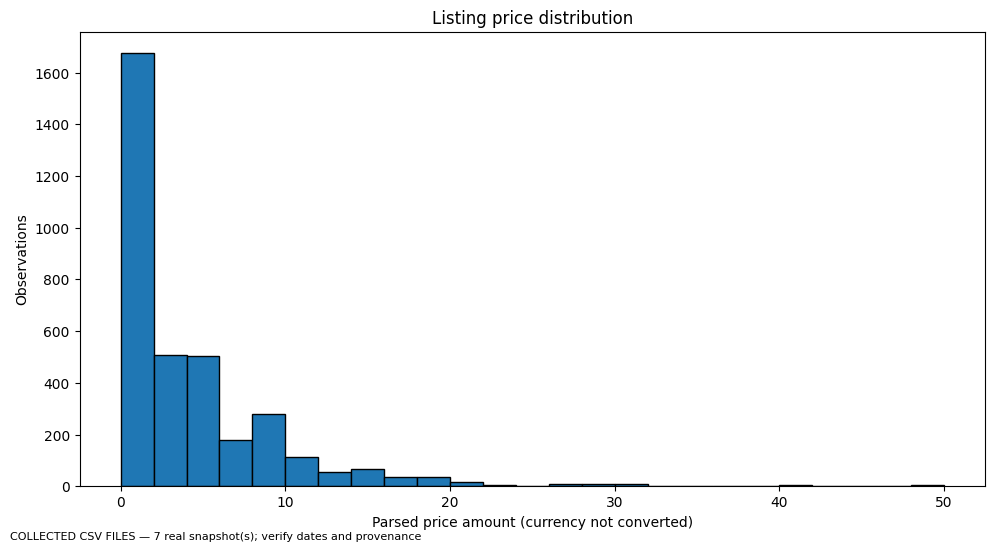

Median=2.00; Q1=0.00; Q3=5.99; IQR outlier count=189


In [5]:
prices=df.loc[df.price_value.notna() & (df.price_value>=0),'price_value']
if len(prices):
 fig,ax=plt.subplots(); ax.hist(prices,bins=25,edgecolor='black'); ax.set(title='Listing price distribution',xlabel='Parsed price amount (currency not converted)',ylabel='Observations'); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()
 q1,q3=prices.quantile(.25),prices.quantile(.75); iqr=q3-q1; out=prices[(prices<q1-1.5*iqr)|(prices>q3+1.5*iqr)]
 print(f'Median={prices.median():.2f}; Q1={q1:.2f}; Q3={q3:.2f}; IQR outlier count={len(out)}')
else: print('No usable numeric prices.')

### Interpretation: Listing price distribution

**What you see:** Most bars are on the left. The tallest bar (prices from 0 to about 2) holds about 1,700 observations. The bars get shorter as the price goes up, and a few listings reach 30 to 50.

**What it means, step by step:**
1. Most top sellers are cheap or free. The **median price is 2.00**.
2. Q1 is 0, so at least one quarter of the observations cost nothing.
3. Q3 is 5.99, so **three out of four observations cost 5.99 or less**.
4. The shape is **right-skewed**: a long tail of expensive games stretches to the right.
5. The IQR rule gives an upper fence of about 15 (Q3 + 1.5 × IQR ≈ 14.98). Prices above it are outliers, and the code found **189 outliers**.

**Why this matters:** Because of the skew, the median (2.00) describes a typical price better than the average would. The few expensive games pull the average up.

**Be careful:** The currency is not converted. Each game can appear up to 7 times (once per daily snapshot), so these are *observations*, not unique games.

## 4. Question 2 — Is price related to rank?

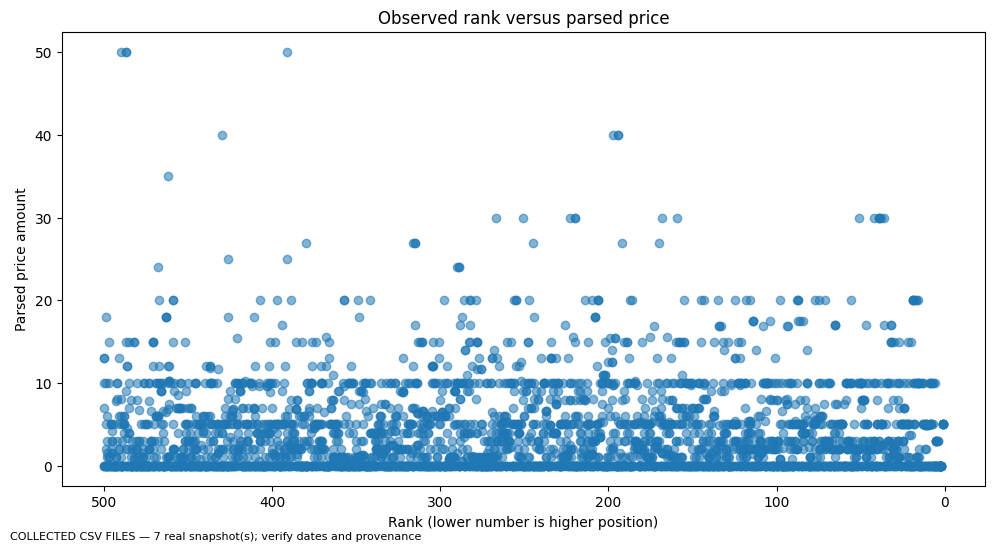

Spearman correlation: -0.044
Review counts/ratings are not in the assigned fields; do not claim a correlation without verified data.


In [6]:
tmp=df.dropna(subset=['rank','price_value'])
if len(tmp)>=2:
 fig,ax=plt.subplots(); ax.scatter(tmp['rank'],tmp['price_value'],alpha=.55); ax.invert_xaxis(); ax.set(title='Observed rank versus parsed price',xlabel='Rank (lower number is higher position)',ylabel='Parsed price amount'); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()
 print('Spearman correlation:',round(tmp[['rank','price_value']].corr(method='spearman').iloc[0,1],3))
else: print('Insufficient rank-price pairs.')
print('Review counts/ratings are not in the assigned fields; do not claim a correlation without verified data.')

### Interpretation: Rank versus price

**What you see:** The points are spread over the whole chart. Games near the top of the list (right side, rank 1) and games near the bottom (left side, rank 500) show similar price levels. The points form horizontal rows at 0, 5, 10, 15 and 20 because developers like round prices.

**What it means, step by step:**
1. The Spearman correlation is **-0.044**. A value this close to 0 means there is almost no relationship.
2. Cheap, medium and expensive games all appear at both the top and the bottom of the list.
3. The small negative sign only says prices drop very slightly as the rank number grows. The effect is too small to matter.

**Answer to Question 2:** In this data, price does **not** explain rank. Rank is probably driven by things we did not collect, such as sales volume or recent popularity.

**Be careful:**
- About 3,500 points overlap, so dense areas look the same as sparse ones.
- The same game appears on several days, so the points are not fully independent.
- Ratings and review counts were not collected, so we cannot test price against ratings.

## 5. Question 3 — Seven-day change in prices and ranks

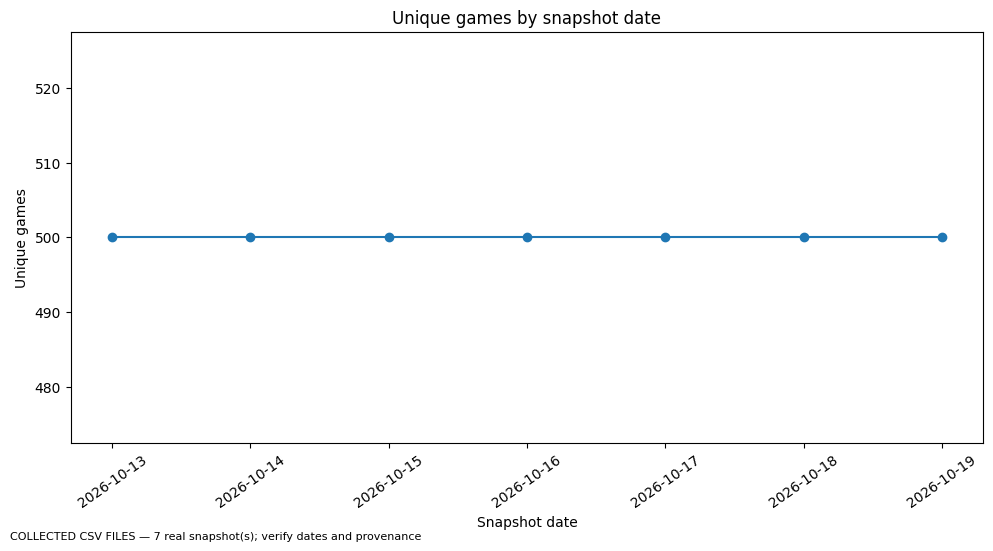

In [9]:
if 'snapshot_date' not in df:
 if 'scraped_at' not in df:
  raise KeyError("Required 'snapshot_date' or source timestamp column 'scraped_at' is missing.")
 df['snapshot_date']=pd.to_datetime(df['scraped_at'],errors='coerce',utc=True).dt.date.astype('string')
daily=df.groupby('snapshot_date',dropna=True).agg(unique_games=('url','nunique'),median_price=('price_value','median')).reset_index()
if len(daily):
 fig,ax=plt.subplots(); ax.plot(daily.snapshot_date,daily.unique_games,marker='o'); ax.set(title='Unique games by snapshot date',xlabel='Snapshot date',ylabel='Unique games'); ax.tick_params(axis='x',rotation=35); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()


### Interpretation: Unique games by snapshot date

**What you see:** A perfectly flat line at **500** for all 7 days (13 to 19 October 2026).

**What it means, step by step:**
1. Every snapshot has exactly 500 games. This is because the scraper collects the **top 500** each day.
2. So the flat line comes from the collection limit. It does **not** describe the market, and it cannot show growth or decline.
3. The useful signal is somewhere else. Across all 7 days there are **852 unique games** in 3,500 observations. If the list never changed, there would be only 500. So about 352 extra games entered the top 500 at some point, and an average game stayed on the list for about 4 of the 7 days.

**Be careful:** The y-axis is zoomed in (about 475 to 525), but the line is flat, so nothing is hidden. A more useful chart would show how many games *entered* and *left* the list each day.

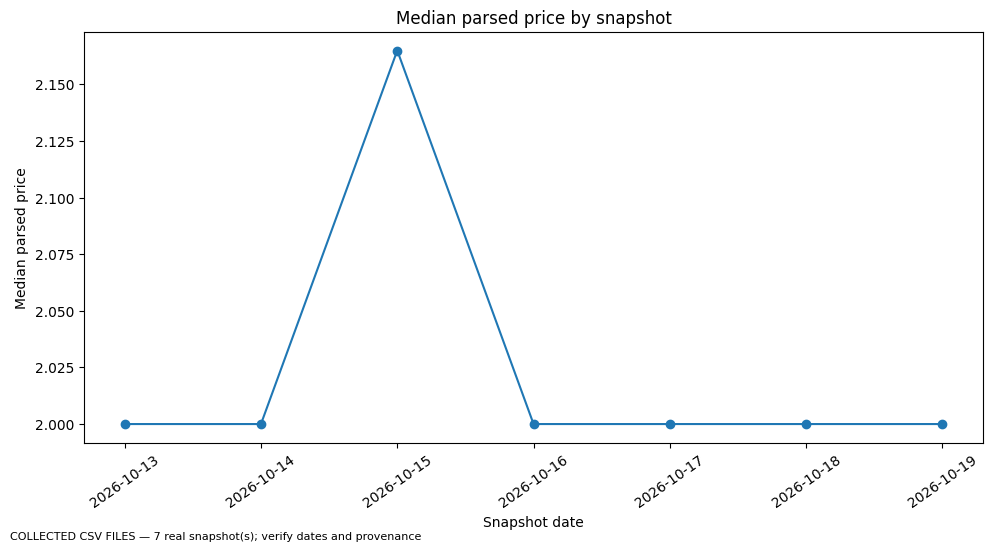

In [ ]:
if len(daily):
 fig,ax=plt.subplots(); ax.plot(daily.snapshot_date,daily.median_price,marker='o'); ax.set(title='Median parsed price by snapshot',xlabel='Snapshot date',ylabel='Median parsed price'); ax.tick_params(axis='x',rotation=35); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()


### Interpretation: Median parsed price by snapshot

**What you see:** The median price is 2.00 on six of the seven days. On 15 October it rises to about 2.17.

**What it means, step by step:**
1. The typical price stays the same across the week, so there is **no real price trend**.
2. The peak looks big, but the change is only about **17 cents**. The y-axis runs from 2.00 to only about 2.15, which makes a tiny change look large.
3. 15 October is also the first day when many games change rank a lot (see the next chart). A different mix of games in the list that day may explain the small rise.

**Be careful:** This is the median only, from just 7 points, and the currency is not converted. Do not call it a trend or a price increase.

,snapshot_date,2026-10-13,2026-10-14,2026-10-15,2026-10-16,2026-10-17,2026-10-18,2026-10-19,rank_range
url,title,,,,,,,,
https://seenthai.itch.io/this-role-you-are-hamster,This Role: You are Hamster,79.0,79.0,324.0,457.0,NaN,90.0,79.0,378.0
https://aeon-star-interactive.itch.io/steel-legion,Steel Legion,NaN,NaN,115.0,152.0,216.0,492.0,NaN,377.0
https://futurecatgames.itch.io/oneshot,OneShot,123.0,123.0,499.0,305.0,238.0,177.0,123.0,376.0
https://curepotion.itch.io/isolated-inhale,Isolated Inhale,122.0,122.0,257.0,326.0,498.0,164.0,148.0,376.0
https://dacuriblue.itch.io/thegardener,The Gardener,358.0,358.0,122.0,140.0,222.0,498.0,358.0,376.0
https://neprojects.itch.io/project-depot-shift,Project: Depot Shift,33.0,33.0,NaN,395.0,53.0,35.0,33.0,362.0
https://tjlazer.itch.io/bruce-lee-st,Bruce Lee for Atari ST,440.0,440.0,85.0,114.0,156.0,264.0,442.0,357.0
https://tuyoki.itch.io/dwellers-empty-path,Dweller's Empty Path,101.0,101.0,NaN,443.0,151.0,102.0,103.0,342.0
https://koniipinka.itch.io/iso2004-chapter1,ISO/2004 [Chapter#1],117.0,117.0,341.0,456.0,331.0,212.0,116.0,340.0


C:\Users\danie\AppData\Local\Temp\ipykernel_20796\1415734225.py:12: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig,ax=plt.subplots(); top.rank_range.plot(kind='bar',ax=ax); ax.set(title='Top listings by observed rank movement',xlabel='Game title',ylabel='Max rank − min rank'); ax.tick_params(axis='x',rotation=65); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()


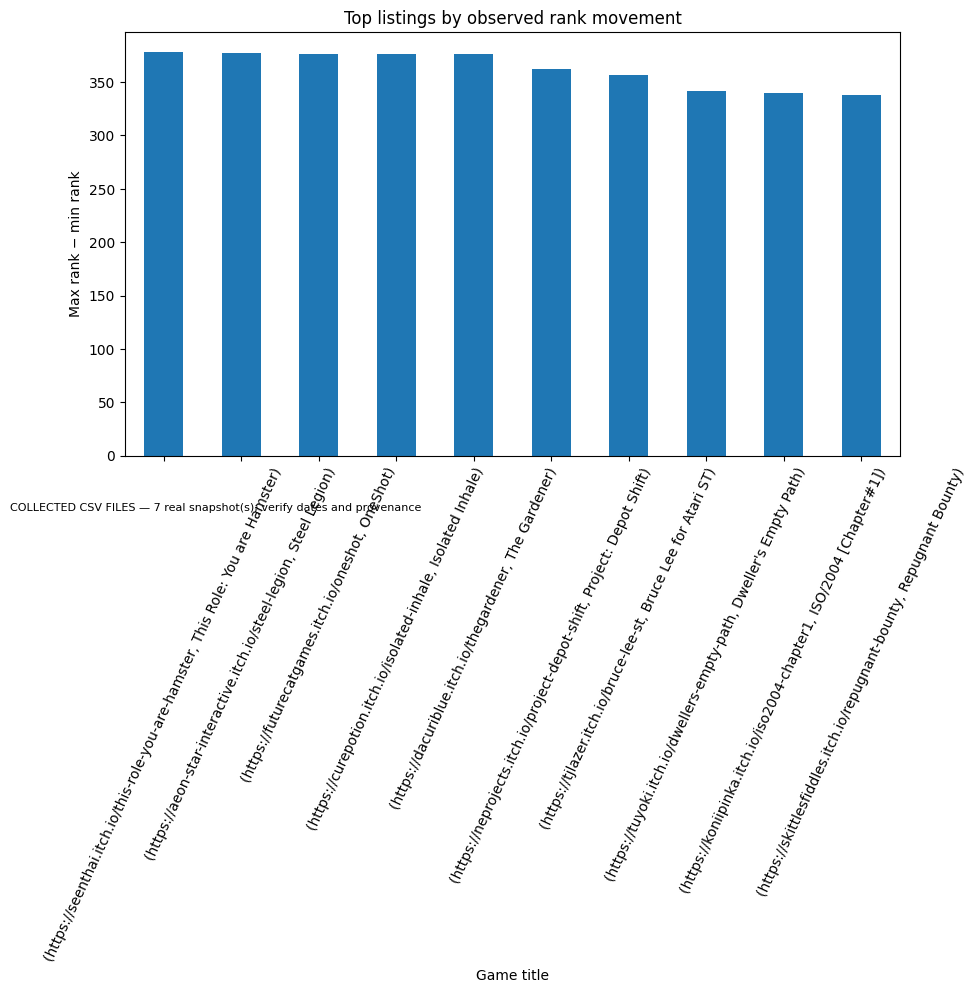

In [ ]:
piv=df.dropna(subset=['rank','snapshot_date']).pivot_table(index=['url','title'],columns='snapshot_date',values='rank',aggfunc='first')
if piv.shape[1]>=2:
 piv['rank_range']=piv.max(axis=1)-piv.min(axis=1); top=piv.sort_values('rank_range',ascending=False).head(10); display(top)
 fig,ax=plt.subplots(); top.rank_range.plot(kind='bar',ax=ax); ax.set(title='Top listings by observed rank movement',xlabel='Game title',ylabel='Max rank − min rank'); ax.tick_params(axis='x',rotation=65); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()
else: print('Rank movement requires at least two distinct snapshot dates. One snapshot cannot show a trend.')

### Interpretation: Top listings by observed rank movement (chart and table)

**What you see:** All 10 bars are very tall (about 340 to 378). The biggest are *This Role: You are Hamster* (378), *Steel Legion* (377), and *OneShot*, *Isolated Inhale* and *The Gardener* (376 each).

**What it means, step by step:**
1. `rank_range` is the worst rank number minus the best rank number. For *This Role: You are Hamster* the ranks went from 79 to 457, so the range is 378.
2. Look at the table. On **13 Oct, 14 Oct and 19 Oct** the ranks are almost the same (for example *OneShot*: 123, 123, 123, and *The Gardener*: 358, 358, 358).
3. On **15 to 18 Oct** the same games jump to very different ranks (for example *OneShot*: 499, 305, 238, 177).
4. Real games rarely move 300 places and then return to almost the same place. This pattern suggests the list order on 15 to 18 Oct may have been different (a different sorting, page order or scraping issue). It may not be a real change in popularity.

**What to do:** Check the scraper and the raw files for those dates **before** saying these games "rose" or "fell". If the data is correct, report it honestly as a very unstable ranking.

**Be careful:**
- The bars show the *size* of the move, not the direction.
- Days when a game is missing from the top 500 are ignored in the calculation.
- The x-axis labels show the URL and the title. Showing only the title would be easier to read.

## 6. Question 4 — Which developers dominate the observed list?

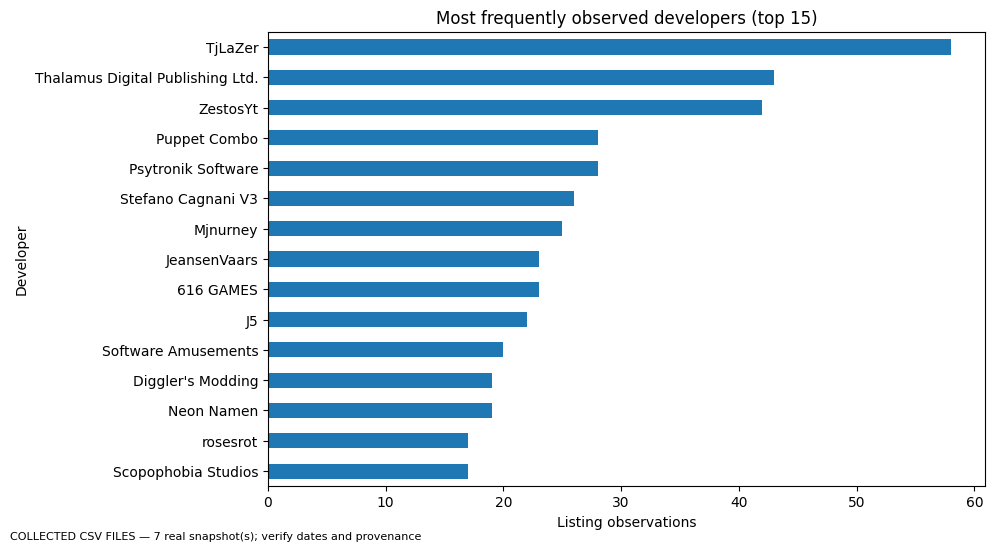

In [8]:
dev=df.developer.dropna().astype(str).str.strip(); dev=dev[dev.ne('')].value_counts().head(15)
if len(dev):
 fig,ax=plt.subplots(); dev.sort_values().plot(kind='barh',ax=ax); ax.set(title='Most frequently observed developers (top 15)',xlabel='Listing observations',ylabel='Developer'); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()
else: print('Developer data unavailable.')

### Interpretation: Most frequently observed developers (top 15)

**What you see:** *TjLaZer* is first with about 58 observations. *Thalamus Digital Publishing Ltd.* (about 43) and *ZestosYt* (about 42) follow. The other 12 developers are between about 17 and 28.

**What it means, step by step:**
1. The leader has about 58 out of 3,500 observations, which is only about 1.7%.
2. The top 15 developers together make roughly 12% of all observations.
3. So **no single developer dominates**. The list is a long tail of many different creators, with a few active ones appearing more often.
4. A high count can mean *several games* from the same developer, or *one game* that stayed on the list for many days.

**Answer to Question 4:** *TjLaZer*, *Thalamus Digital Publishing* and *ZestosYt* appear most often, but none of them controls a large share of the list.

**Be careful:** This counts how often a developer *appears in the list*. It is not market share or sales, because sales were not collected.

## 7. Question 5 — Free/paid share and discounts

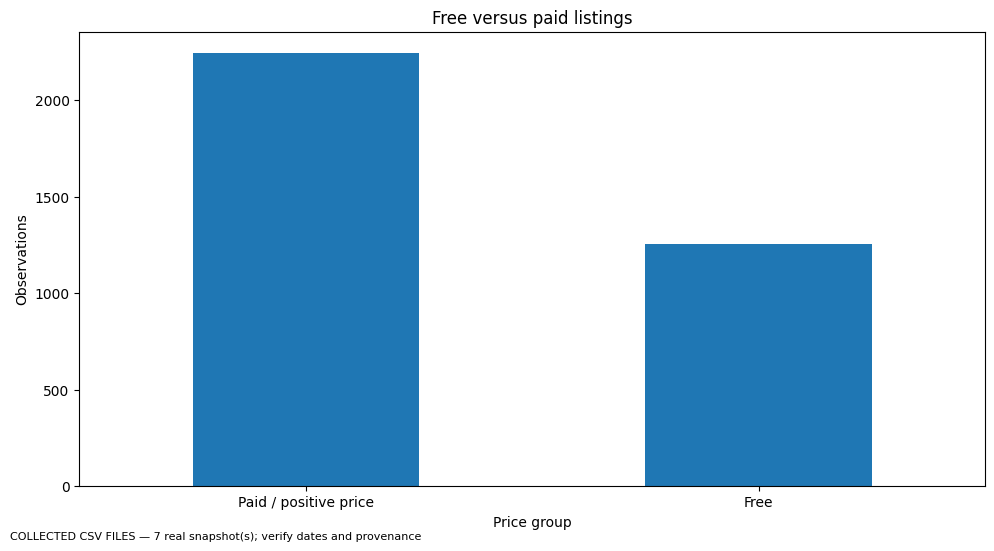

Free share: 35.9 %
Discounts: only calculate if verified old and current prices are available. If absent, state that discount size is not measurable from the assigned fields.


In [5]:
priced=df.dropna(subset=['price_value']).copy()
if len(priced):
 counts=pd.Series(np.where(priced.price_value.eq(0),'Free','Paid / positive price')).value_counts()
 fig,ax=plt.subplots(); counts.plot(kind='bar',ax=ax); ax.set(title='Free versus paid listings',xlabel='Price group',ylabel='Observations'); ax.tick_params(axis='x',rotation=0); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()
 print('Free share:',round(100*priced.price_value.eq(0).mean(),1),'%')
else: print('No usable price data.')
print('Discounts: only calculate if verified old and current prices are available. If absent, state that discount size is not measurable from the assigned fields.')

### Interpretation: Free versus paid listings

**What you see:** The paid bar is taller, at about 2,250 observations. The free bar is about 1,250.

**What it means, step by step:**
1. The code reports a **free share of 35.9%**, so about 36 out of every 100 observations are free.
2. The other 64% have a price above 0.
3. So top sellers on itch.io are mostly paid, but free games still make up a big part of the list.

**Be careful:**
- Some prices are saved as the text "Free / no price displayed" and the code turns them into 0. So "free" may also include games with no visible price, for example pay-what-you-want games.
- These are observations over 7 days, not unique games.
- **Discounts cannot be measured.** We do not have old and new prices, so we should say this clearly in the report.

## 8. Original question — Which genres and platforms are most common?

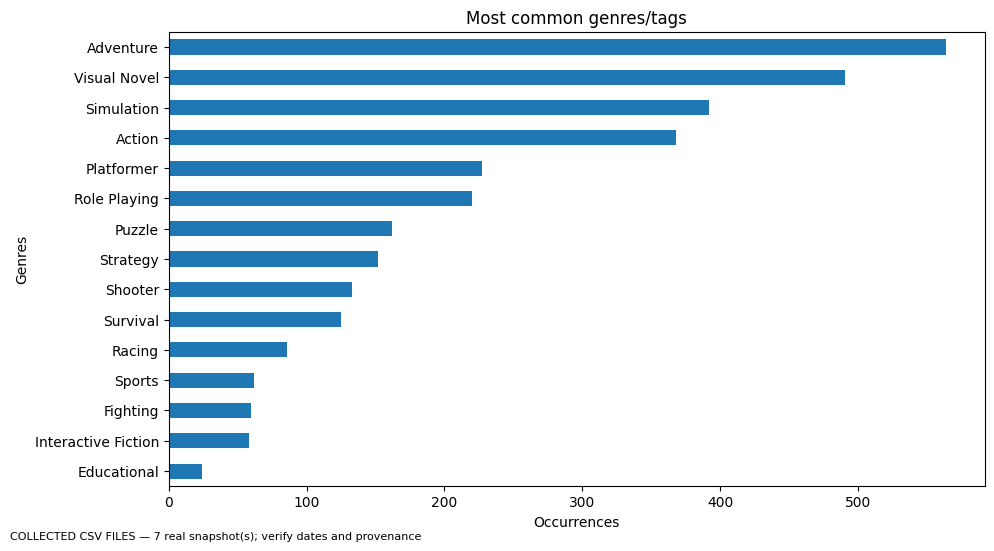

In [6]:
def label_counts(series):
 vals=series.dropna().astype(str).str.split(r'\s*\|\s*').explode().str.strip()
 return vals[vals.ne('') & vals.str.lower().ne('nan')].value_counts().head(15)
for col,title in [('genres','Most common genres/tags')]:
 counts=label_counts(df[col])
 if len(counts):
  fig,ax=plt.subplots(); counts.sort_values().plot(kind='barh',ax=ax); ax.set(title=title,xlabel='Occurrences',ylabel=col.title()); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()
 else: print('No',col,'labels found; verify selectors and report missingness.')

### Interpretation: Most common genres/tags

**What you see:** *Adventure* is the longest bar (about 565). *Visual Novel* (about 490), *Simulation* (about 390) and *Action* (about 370) follow. The shortest bars are *Interactive Fiction* (about 58) and *Educational* (about 24).

**What it means, step by step:**
1. The **top four genres** (Adventure, Visual Novel, Simulation, Action) are far ahead of the rest.
2. *Platformer* and *Role Playing* form a middle group at about 220 to 230.
3. After that the counts fall steadily, down to *Educational*.

**Answer to the original question (genres):** Adventure and Visual Novel are the most common genres in the top sellers.

**Be careful:**
- Genre is **missing for 9.6%** of the rows (337 rows).
- A game can have more than one genre, so one game can be counted several times and the bars add up to more than the number of games.
- The counts are observations across 7 days, not unique games.

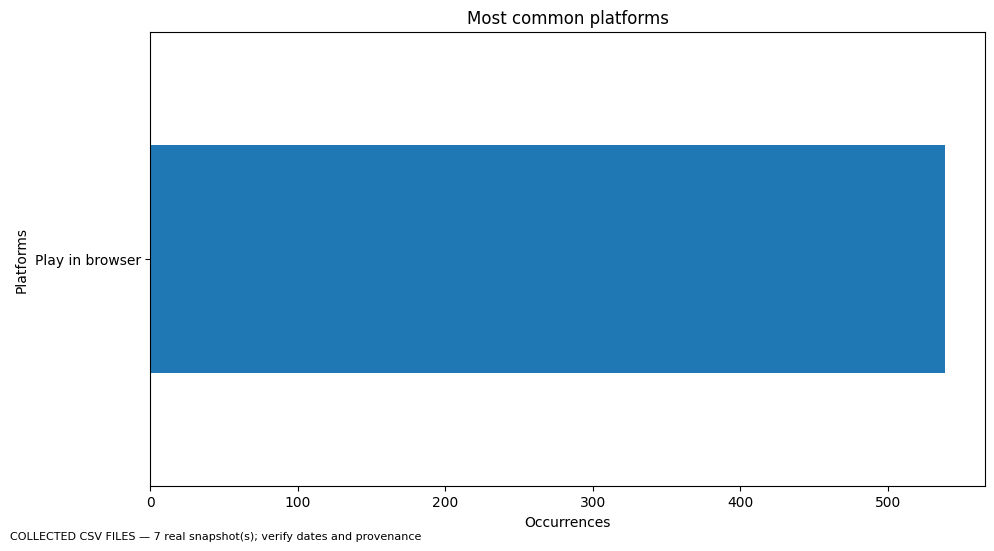

In [ ]:
for col,title in [('platforms','Most common platforms')]:
 counts=label_counts(df[col])
 if len(counts):
  fig,ax=plt.subplots(); counts.sort_values().plot(kind='barh',ax=ax); ax.set(title=title,xlabel='Occurrences',ylabel=col.title()); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()
 else: print('No',col,'labels found; verify selectors and report missingness.')

### Interpretation: Most common platforms

**What you see:** There is only **one bar**: *Play in browser*, with about 540 occurrences.

**What it means, step by step:**
1. The platform field is **missing for 84.6%** of the rows (2,961 out of 3,500). Only about 540 rows have a value, and all of them say "Play in browser".
2. This does **not** mean that browser games are the most common platform. It means the scraper captured only that one label.
3. Windows, macOS, Linux and Android were most likely not captured. A likely reason is that itch.io shows them as small icons, not as text, so the scraper did not read them.

**Answer to the original question (platforms):** We cannot answer it properly with this data. We can only say that at least about 15% of the observations (540 out of 3,500) are playable in the browser.

**What to do:** Check the platform selector in the scraper and collect the platform icons or the page data. If it cannot be fixed, report the platform data as **incomplete** in the limitations section.

## 9. Additional chart — price variation by genre

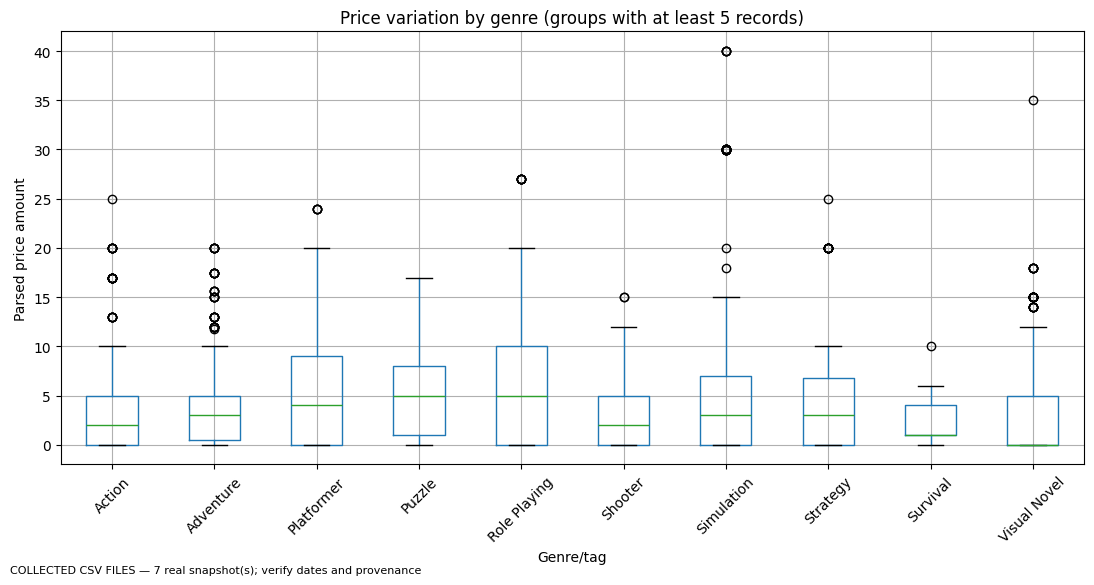

In [7]:
box=df.dropna(subset=['price_value','genres']).copy(); box['genre_first']=box.genres.astype(str).str.split(r'\s*\|\s*').str[0]
counts=box.genre_first.value_counts(); box=box[box.genre_first.isin(counts[counts>=5].head(10).index)]
if len(box):
 fig,ax=plt.subplots(figsize=(11,6)); box.boxplot(column='price_value',by='genre_first',ax=ax,rot=45); ax.set_title('Price variation by genre (groups with at least 5 records)'); ax.set_xlabel('Genre/tag'); ax.set_ylabel('Parsed price amount'); fig.suptitle(''); fig.text(.01,.01,DATA_MODE,fontsize=8); plt.tight_layout(); plt.show()
else: print('Insufficient data for genre price boxplot.')

### Interpretation: Price variation by genre

**How to read a boxplot:** The box holds the middle 50% of prices. The green line is the median. The whiskers show the normal range, and the circles are outliers.

**What you see:**
- **Visual Novel** has a median of 0, so more than half of its listings are free.
- **Survival** is cheap with a median of about 1, and its box is the narrowest (about 1 to 4).
- **Action** and **Shooter** have a median of about 2.
- **Adventure**, **Simulation** and **Strategy** have a median of about 3.
- **Platformer** has a median of about 4, and **Puzzle** and **Role Playing** have the highest medians at about 5.
- **Platformer**, **Role Playing** and **Puzzle** have the widest boxes (up to about 10), so their prices vary the most.

**What it means:**
1. Genre has some link with price, but the differences between medians are small (a few currency units).
2. Almost every genre has outliers. *Simulation* has the highest, at about 30 to 40, and *Visual Novel* has one at about 35.

**Be careful:**
- Only the **first genre** of each game is used, and only genres with at least 5 records.
- The stacked circles are often the *same game* seen on several days.
- The currency is not converted, so this is a description of the data, not proof that genre causes price.

## 10. Final evidence and limitations

In [9]:
display(pd.DataFrame([
 ('Price distribution/outliers','Use histogram and IQR output; state real values only.'),
 ('Price vs rating/reviews or rank','Rank-price analysis is possible; rating/review-count fields are not assigned.'),
 ('Seven-day change','Requires seven distinct actual dates; use rank movement only when available.'),
 ('Developer dominance','Frequency chart measures observations in this list, not total market share.'),
 ('Discounts','Not measurable unless verified old and current prices are collected.'),
 ('Original question','Genre/platform frequency charts answer which labels appear most often.')],columns=['Question','Evidence / limitation']))
print('DATA MODE:',DATA_MODE,'| snapshot count:',df.snapshot_date.nunique())


,Question,Evidence / limitation
0,Price distribution/outliers,Use histogram and IQR output; state real value...
1,Price vs rating/reviews or rank,Rank-price analysis is possible; rating/review...
2,Seven-day change,Requires seven distinct actual dates; use rank...
3,Developer dominance,Frequency chart measures observations in this ...
4,Discounts,Not measurable unless verified old and current...
5,Original question,Genre/platform frequency charts answer which l...


DATA MODE: COLLECTED CSV FILES — 7 real snapshot(s); verify dates and provenance | snapshot count: 7
